# Проверка качества моделей VehicleReID (Colab)

Считает метрики для раздела «Расчет надежности»:
- **ReID-экстрактор** на VeRi-776 (1 678 query / 11 579 gallery): базовый режим и режим flip-TTA + re-ranking;
- **детектор ТС** на валидационной выборке (Precision, Recall, mAP@50, mAP@50-95).

Перед запуском: `Среда выполнения → Сменить тип → GPU (T4)`. Ячейки запускайте по порядку.
Ячейка 3 ищет файлы на Drive, ячейка 4 подставляет найденные пути (при необходимости впишите свои).
Код проекта (папка `ml/`, включая новый `ml/detection/evaluate_detector.py`) должен лежать на Drive, например в `MyDrive/VehicleReID/code/ml`.

In [20]:
import torch
print('CUDA доступна:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

CUDA доступна: True Tesla T4


In [3]:
# 1. GPU и зависимости
!nvidia-smi -L
!pip -q install ultralytics

GPU 0: Tesla T4 (UUID: GPU-7a0da29d-3453-b322-8df5-14327b21bd66)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.8 MB/s eta 0:00:00


In [5]:
# 2. Подключение Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
# 3. Поиск нужных файлов на Drive (может занять около минуты)
import glob, os
ROOT = '/content/drive/MyDrive/VehicleReID'
assert os.path.isdir(ROOT), f'Папка {ROOT} не найдена: проверьте название папки проекта на Drive'

def find(pattern):
    return sorted(glob.glob(f'{ROOT}/**/{pattern}', recursive=True))

FOUND = {
    'ReID-чекпоинты (best_checkpoint.pt)': find('best_checkpoint.pt'),
    'Веса детектора (best.pt)':           find('best.pt'),
    'data.yaml детектора':                find('data.yaml'),
    'Протокол VeRi (name_query.txt)':     find('name_query.txt'),
    'Папки image_query (VeRi/CityFlow)':  find('image_query'),
    'Архивы .zip':                        find('*.zip'),
    'ml/reid/evaluate.py':                find('ml/reid/evaluate.py'),
    'evaluate_detector.py':               find('evaluate_detector.py'),
}
for title, items in FOUND.items():
    print(f'\n== {title}: {len(items)}')
    for p in items[:15]:
        print('  ', p)


== ReID-чекпоинты (best_checkpoint.pt): 4
   /content/drive/MyDrive/VehicleReID/checkpoints/best_checkpoint.pt
   /content/drive/MyDrive/VehicleReID/checkpoints_ablation_random_erasing/best_checkpoint.pt
   /content/drive/MyDrive/VehicleReID/checkpoints_cityflow_finetune/best_checkpoint.pt
   /content/drive/MyDrive/VehicleReID/code/ml/reid/checkpoints/best_checkpoint.pt

== Веса детектора (best.pt): 2
   /content/drive/MyDrive/VehicleReID/code/ml/detection/runs/vehicle_detector/weights/best.pt
   /content/drive/MyDrive/VehicleReID/detection_runs/vehicle_detector/weights/best.pt

== data.yaml детектора: 0

== Протокол VeRi (name_query.txt): 0

== Папки image_query (VeRi/CityFlow): 0

== Архивы .zip: 3
   /content/drive/MyDrive/VehicleReID/data/VeRi.zip
   /content/drive/MyDrive/VehicleReID/data/cityflow_veri_subset.zip
   /content/drive/MyDrive/VehicleReID/data/detection_yolo_subset.zip

== ml/reid/evaluate.py: 1
   /content/drive/MyDrive/VehicleReID/code/ml/reid/evaluate.py

== evalua

In [22]:
# 4. Пути. Оставьте None, чтобы взять первый найденный вариант, или впишите свой путь.
# Если вариантов несколько, обязательно проверьте, что выбран нужный (см. вывод ячейки 3).
REID_CKPT   = f'{ROOT}/checkpoints/best_checkpoint.pt'  # базовая модель (эпоха 59), НЕ checkpoints_cityflow_finetune
VERI_SRC    = None   # папка VeRi (с image_query/image_test) ИЛИ zip-архив с ней
DET_WEIGHTS = f'{ROOT}/detection_runs/vehicle_detector/weights/best.pt'
DET_YAML    = None   # data.yaml детектора; рядом должны лежать images/val и labels/val
CODE_SRC    = None   # папка, внутри которой лежит ml/ (например .../VehicleReID/code)

def first(lst, cond=lambda p: True):
    for p in lst:
        if cond(p): return p
    return None

if VERI_SRC is None:
    d = first(FOUND['Папки image_query (VeRi/CityFlow)'], lambda p: 'cityflow' not in p.lower())
    VERI_SRC = os.path.dirname(d) if d else first(FOUND['Архивы .zip'], lambda p: 'veri' in p.lower())
if DET_WEIGHTS is None:
    DET_WEIGHTS = first(FOUND['Веса детектора (best.pt)'], lambda p: 'detect' in p.lower()) or first(FOUND['Веса детектора (best.pt)'])
if DET_YAML is None:
    DET_YAML = first(FOUND['data.yaml детектора'])
if CODE_SRC is None:
    e = first(FOUND['ml/reid/evaluate.py'])
    CODE_SRC = e[:-len('/ml/reid/evaluate.py')] if e else None

paths = {'REID_CKPT': REID_CKPT, 'VERI_SRC': VERI_SRC, 'DET_WEIGHTS': DET_WEIGHTS, 'DET_YAML': DET_YAML, 'CODE_SRC': CODE_SRC}
bad = []
for k, v in paths.items():
    ok = bool(v) and os.path.exists(v)
    print(('OK  ' if ok else 'НЕТ ') + f'{k}: {v}')
    if not ok: bad.append(k)
if bad:
    print('\nНе найдено:', ', '.join(bad), '- впишите путь вручную выше и запустите ячейку снова.')

OK  REID_CKPT: /content/drive/MyDrive/VehicleReID/checkpoints/best_checkpoint.pt
OK  VERI_SRC: /content/drive/MyDrive/VehicleReID/data/VeRi.zip
OK  DET_WEIGHTS: /content/drive/MyDrive/VehicleReID/detection_runs/vehicle_detector/weights/best.pt
НЕТ DET_YAML: None
OK  CODE_SRC: /content/drive/MyDrive/VehicleReID/code

Не найдено: DET_YAML - впишите путь вручную выше и запустите ячейку снова.


In [8]:
# 5. Код проекта -> локальный диск Colab
import shutil, sys
assert CODE_SRC and os.path.isdir(f'{CODE_SRC}/ml'), 'Скопируйте папку ml/ проекта на Drive и укажите CODE_SRC'
shutil.rmtree('/content/project', ignore_errors=True)
shutil.copytree(f'{CODE_SRC}/ml', '/content/project/ml', ignore=shutil.ignore_patterns('__pycache__', 'runs', 'exported', 'checkpoints'))
for need in ['ml/reid/evaluate.py', 'ml/detection/evaluate_detector.py']:
    print(('OK  ' if os.path.isfile(f'/content/project/{need}') else 'НЕТ ') + need)

OK  ml/reid/evaluate.py
OK  ml/detection/evaluate_detector.py


In [9]:
# 6. VeRi-776 -> локальный диск (так быстрее, чем читать с Drive) и проверка протокола
import zipfile, subprocess
LOCAL = '/content/data/VeRi_src'
shutil.rmtree(LOCAL, ignore_errors=True); os.makedirs(LOCAL)
if VERI_SRC.endswith('.zip'):
    with zipfile.ZipFile(VERI_SRC) as z: z.extractall(LOCAL)
else:
    shutil.copytree(VERI_SRC, LOCAL, dirs_exist_ok=True)

# корень = папка, где лежат image_query и image_test (учитываем лишний уровень вложенности)
VERI_ROOT = None
for dp, dn, _ in os.walk(LOCAL):
    if 'image_query' in dn and 'image_test' in dn:
        VERI_ROOT = dp; break
assert VERI_ROOT, 'В данных VeRi не найдены image_query и image_test'
n_q = len(glob.glob(f'{VERI_ROOT}/image_query/*.jpg')); n_g = len(glob.glob(f'{VERI_ROOT}/image_test/*.jpg'))
print('VERI_ROOT =', VERI_ROOT, '| query:', n_q, '| gallery:', n_g, '(ожидается 1678 и 11579)')
for f in ['name_query.txt', 'name_test.txt', 'gt_index.txt', 'jk_index.txt']:
    print(('OK  ' if os.path.isfile(f'{VERI_ROOT}/{f}') else 'НЕТ ') + f)

VERI_ROOT = /content/data/VeRi_src/VeRi | query: 1678 | gallery: 11579 (ожидается 1678 и 11579)
OK  name_query.txt
OK  name_test.txt
OK  gt_index.txt
OK  jk_index.txt


In [ ]:
# 6а. ТОЛЬКО если выше есть «НЕТ» у файлов протокола: сгенерировать их (запускайте, если файлов правда нет)
# !python /content/project/ml/reid/datasets/generate_eval_protocol.py --data-root {VERI_ROOT}

In [10]:
!cd /content/project && PYTHONPATH=/content/project:/content/project/ml/reid python -u -W ignore ml/reid/evaluate.py --data-root {VERI_ROOT} --checkpoint {REID_CKPT} --num-workers 2 2>&1 | grep --line-buffered -v -E "DataLoader|worker_number" | tee /content/reid_baseline.txt

Загружаю чекпоинт: /content/drive/MyDrive/VehicleReID/checkpoints/best_checkpoint.pt
  Эпоха чекпоинта: 59
Загружаю query/gallery (в порядке name_query.txt / name_test.txt)...
  query: 1678, gallery: 11579
Читаю gt_index.txt / jk_index.txt...
  Проверка индексации: совпадение pid при 1-based = 100.0%, при 0-based = 98.1%
  Используется индексация: 1-based
Извлекаю эмбеддинги query...
Извлекаю эмбеддинги gallery...
Считаю mAP/CMC...

Учтено query: 1678 / 1678
mAP:    69.04%
Rank-1: 93.33%
Rank-5: 97.14%
Rank-10: 98.15%
Rank-20: 98.87%


In [11]:
!cd /content/project && PYTHONPATH=/content/project:/content/project/ml/reid python -u -W ignore ml/reid/evaluate.py --data-root {VERI_ROOT} --checkpoint {REID_CKPT} --num-workers 2 --flip-tta --rerank 2>&1 | grep --line-buffered -v -E "DataLoader|worker_number" | tee /content/reid_tta_rerank.txt

Загружаю чекпоинт: /content/drive/MyDrive/VehicleReID/checkpoints/best_checkpoint.pt
  Эпоха чекпоинта: 59
Загружаю query/gallery (в порядке name_query.txt / name_test.txt)...
  query: 1678, gallery: 11579
Читаю gt_index.txt / jk_index.txt...
  Проверка индексации: совпадение pid при 1-based = 100.0%, при 0-based = 98.1%
  Используется индексация: 1-based
Извлекаю эмбеддинги query...
Извлекаю эмбеддинги gallery...
  (flip-TTA включён: эмбеддинг усреднён с горизонтально отражённой версией)
Считаю k-reciprocal re-ranking (k1=20, k2=6, lambda=0.3)... это может занять несколько минут на большой галерее.
Считаю mAP/CMC (по re-ranked дистанциям)...

Учтено query: 1678 / 1678
mAP:    73.91%
Rank-1: 94.46%
Rank-5: 96.48%
Rank-10: 97.85%
Rank-20: 98.69%


In [17]:
# 9. Распаковка валидационного датасета детектора из архива на Drive
import yaml
DET_ZIP = f'{ROOT}/data/detection_yolo_subset.zip'
assert os.path.isfile(DET_ZIP), f'Нет архива {DET_ZIP}'
!unzip -q -o "{DET_ZIP}" -d /content/data
ds_dir = '/content/data/detection_yolo'
print('images/val:', len(glob.glob(f'{ds_dir}/images/val/*')), '(ожидается 573)')
print('labels/val:', len(glob.glob(f'{ds_dir}/labels/val/*')))
cfg = yaml.safe_load(open(f'{ds_dir}/data.yaml', encoding='utf-8'))
cfg['path'] = ds_dir
yaml.safe_dump(cfg, open('/content/det_data.yaml', 'w', encoding='utf-8'), allow_unicode=True)
print(open('/content/det_data.yaml', encoding='utf-8').read())

images/val: 573 (ожидается 573)
labels/val: 573
names:
  0: vehicle
path: /content/data/detection_yolo
train: images/train
val: images/val



In [27]:
print('DET_WEIGHTS:', DET_WEIGHTS, os.path.exists(DET_WEIGHTS))
print('det_data.yaml:', os.path.exists('/content/det_data.yaml'))
!ls -la /content/project/ml/detection/
!wc -l /content/project/ml/detection/evaluate_detector.py
!python -u /content/project/ml/detection/evaluate_detector.py --help

DET_WEIGHTS: /content/drive/MyDrive/VehicleReID/detection_runs/vehicle_detector/weights/best.pt True
det_data.yaml: True
total 80
drwx------ 2 root root  4096 Oct 12 10:39 .
drwx------ 4 root root  4096 Oct 12 10:39 ..
-rw------- 1 root root 37052 Oct  6 10:38 check_detector.py
-rw------- 1 root root     0 Oct 12 10:34 evaluate_detector.py
-rw------- 1 root root  4114 Sep 19 06:40 export_detector.py
-rw------- 1 root root 16210 Sep 19 06:53 prepare_dataset.py
-rw------- 1 root root  5676 Sep 19 06:40 train_detector.py
0 /content/project/ml/detection/evaluate_detector.py


In [28]:
from ultralytics import YOLO
r = YOLO(DET_WEIGHTS).val(data='/content/det_data.yaml', split='val', imgsz=640, batch=16,
                          workers=0, device=0, plots=True, project='/content/det_eval',
                          name='evaluate', exist_ok=True)
m = {'Precision': r.box.mp * 100, 'Recall': r.box.mr * 100, 'mAP@50': r.box.map50 * 100, 'mAP@50-95': r.box.map * 100}
text = '\n'.join(f'{k}: {v:.1f} %' for k, v in m.items())
print(text)
open('/content/det_metrics.txt', 'w', encoding='utf-8').write(text + '\n')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 930.0±536.4 MB/s, size: 68.2 KB)
val: Scanning /content/data/detection_yolo/labels/val... 573 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 573/573 1.8Kit/s 0.3s
val: New cache created: /content/data/detection_yolo/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.6it/s 9.9s
                   all        573       3506      0.772      0.826      0.859      0.661
Speed: 0.3ms preprocess, 5.8ms infe

66

In [26]:
# 10. Метрики детектора (ожидается: Precision ~77.0, Recall ~82.6, mAP@50 ~85.9, mAP@50-95 ~66.0)
!python /content/project/ml/detection/evaluate_detector.py --model {DET_WEIGHTS} --data /content/det_data.yaml --project /content/det_eval --name evaluate --device 0 2>&1 | tee /content/det_metrics.txt

/content/det_eval/evaluate/BoxF1_curve.png


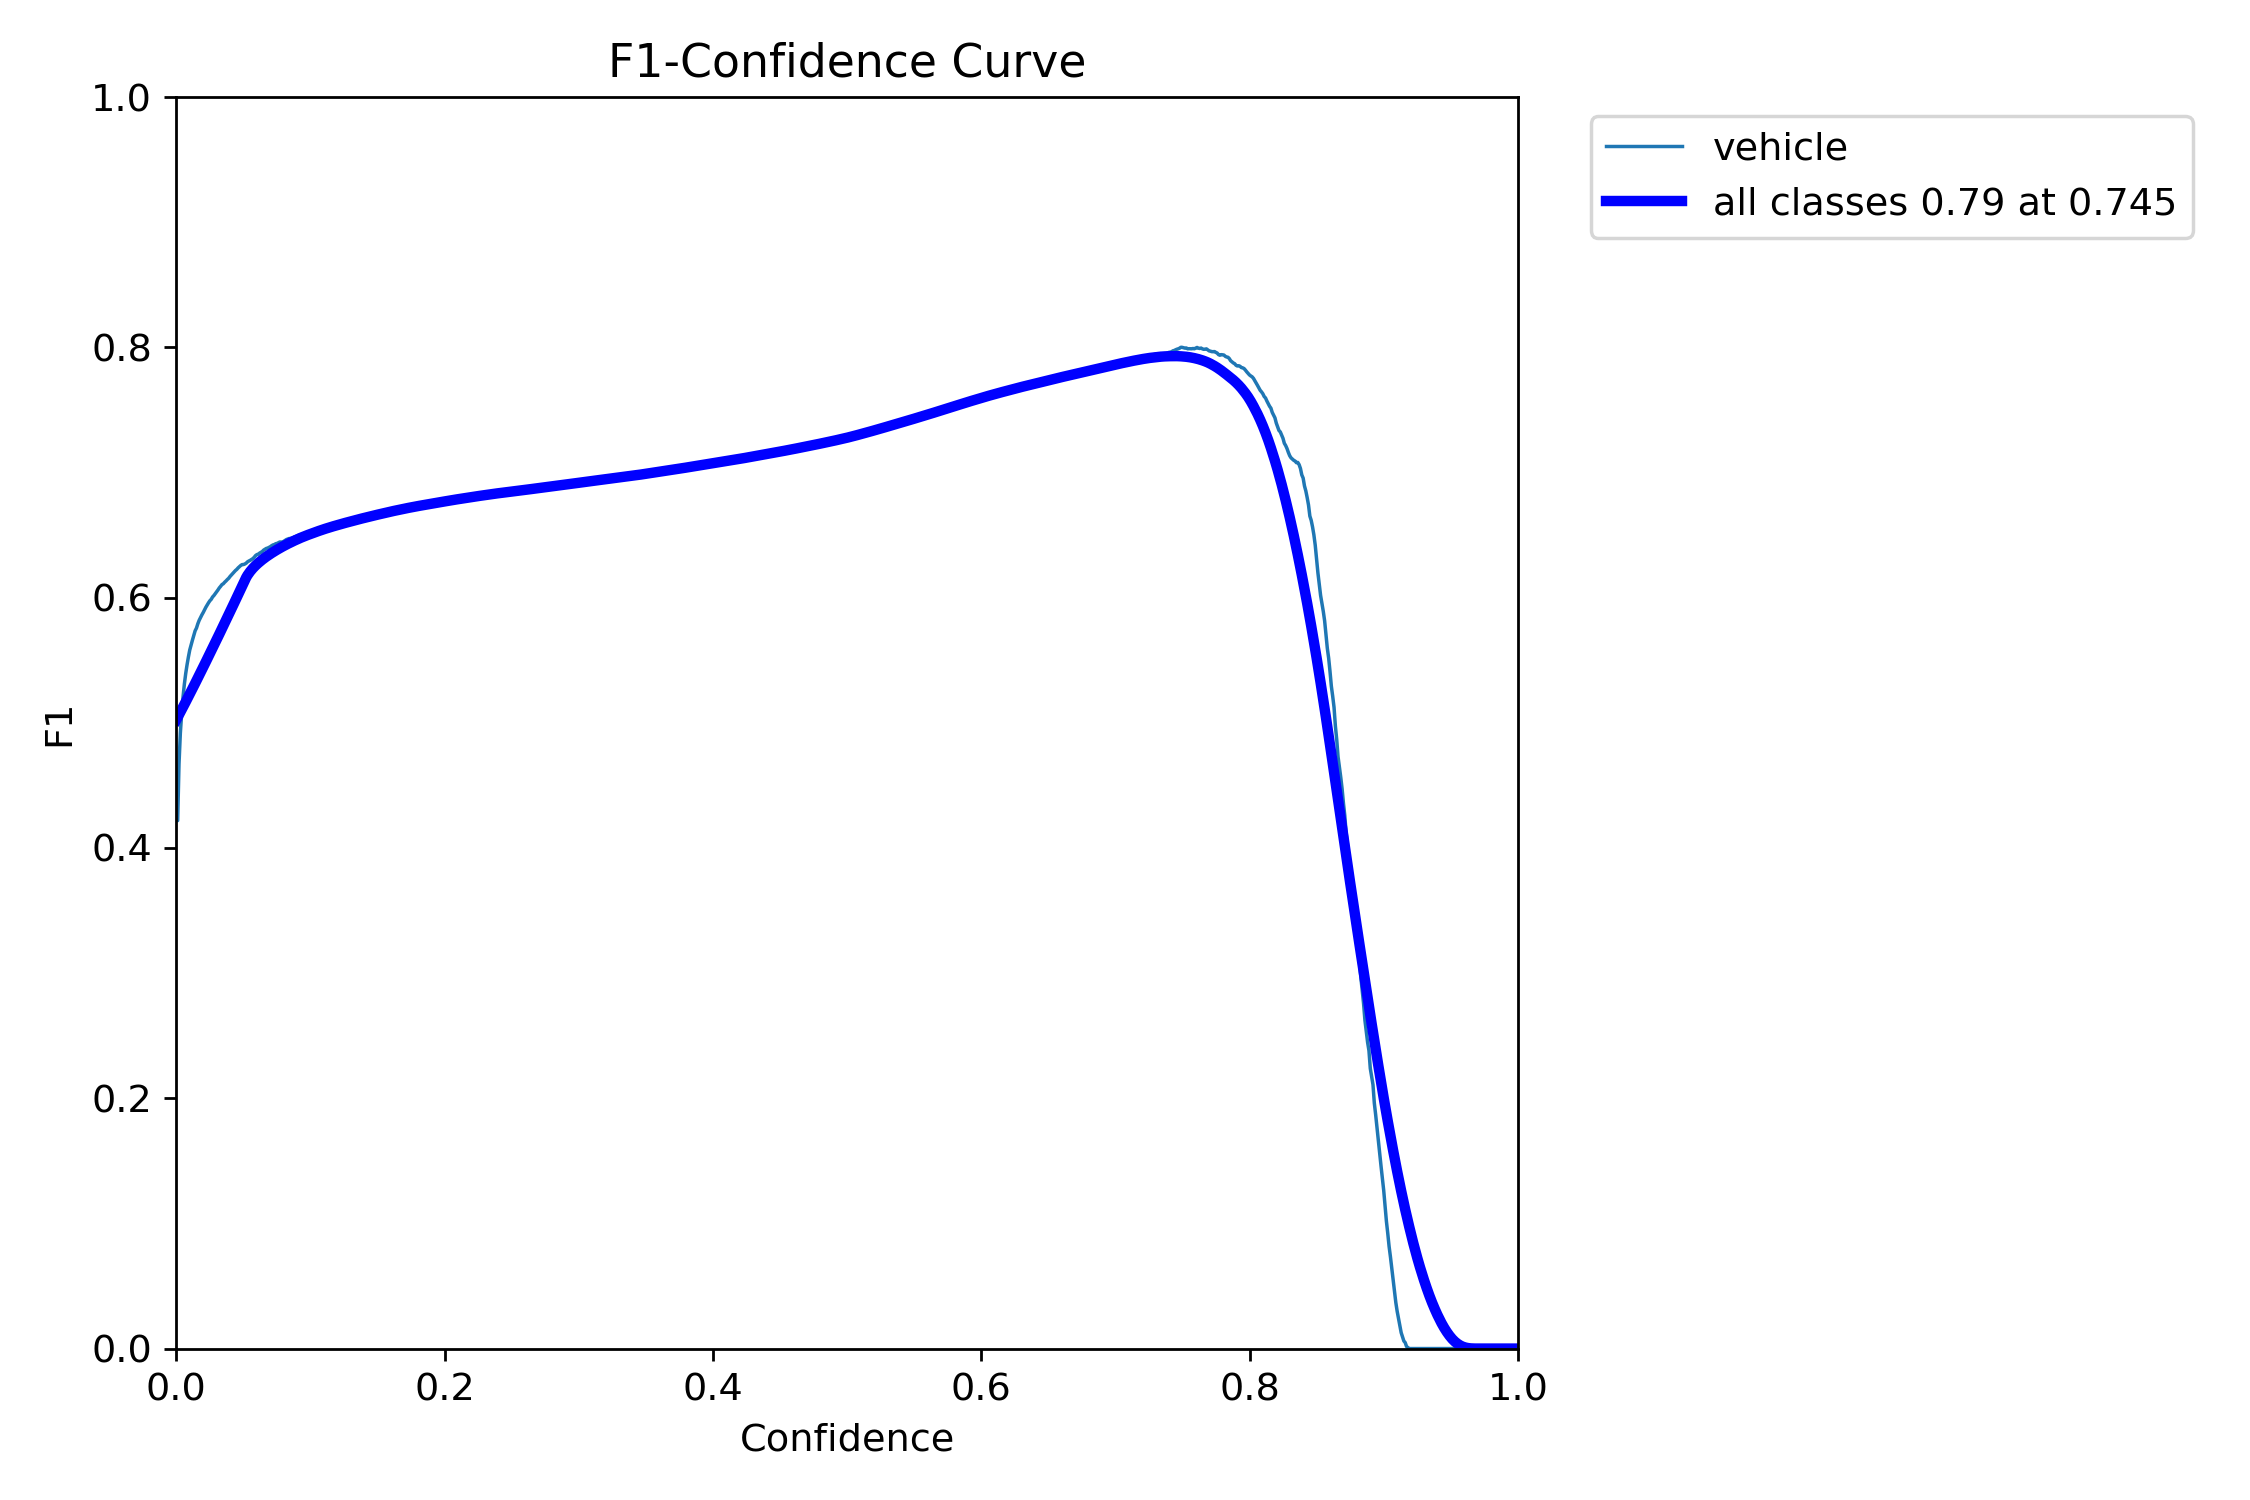

/content/det_eval/evaluate/BoxPR_curve.png


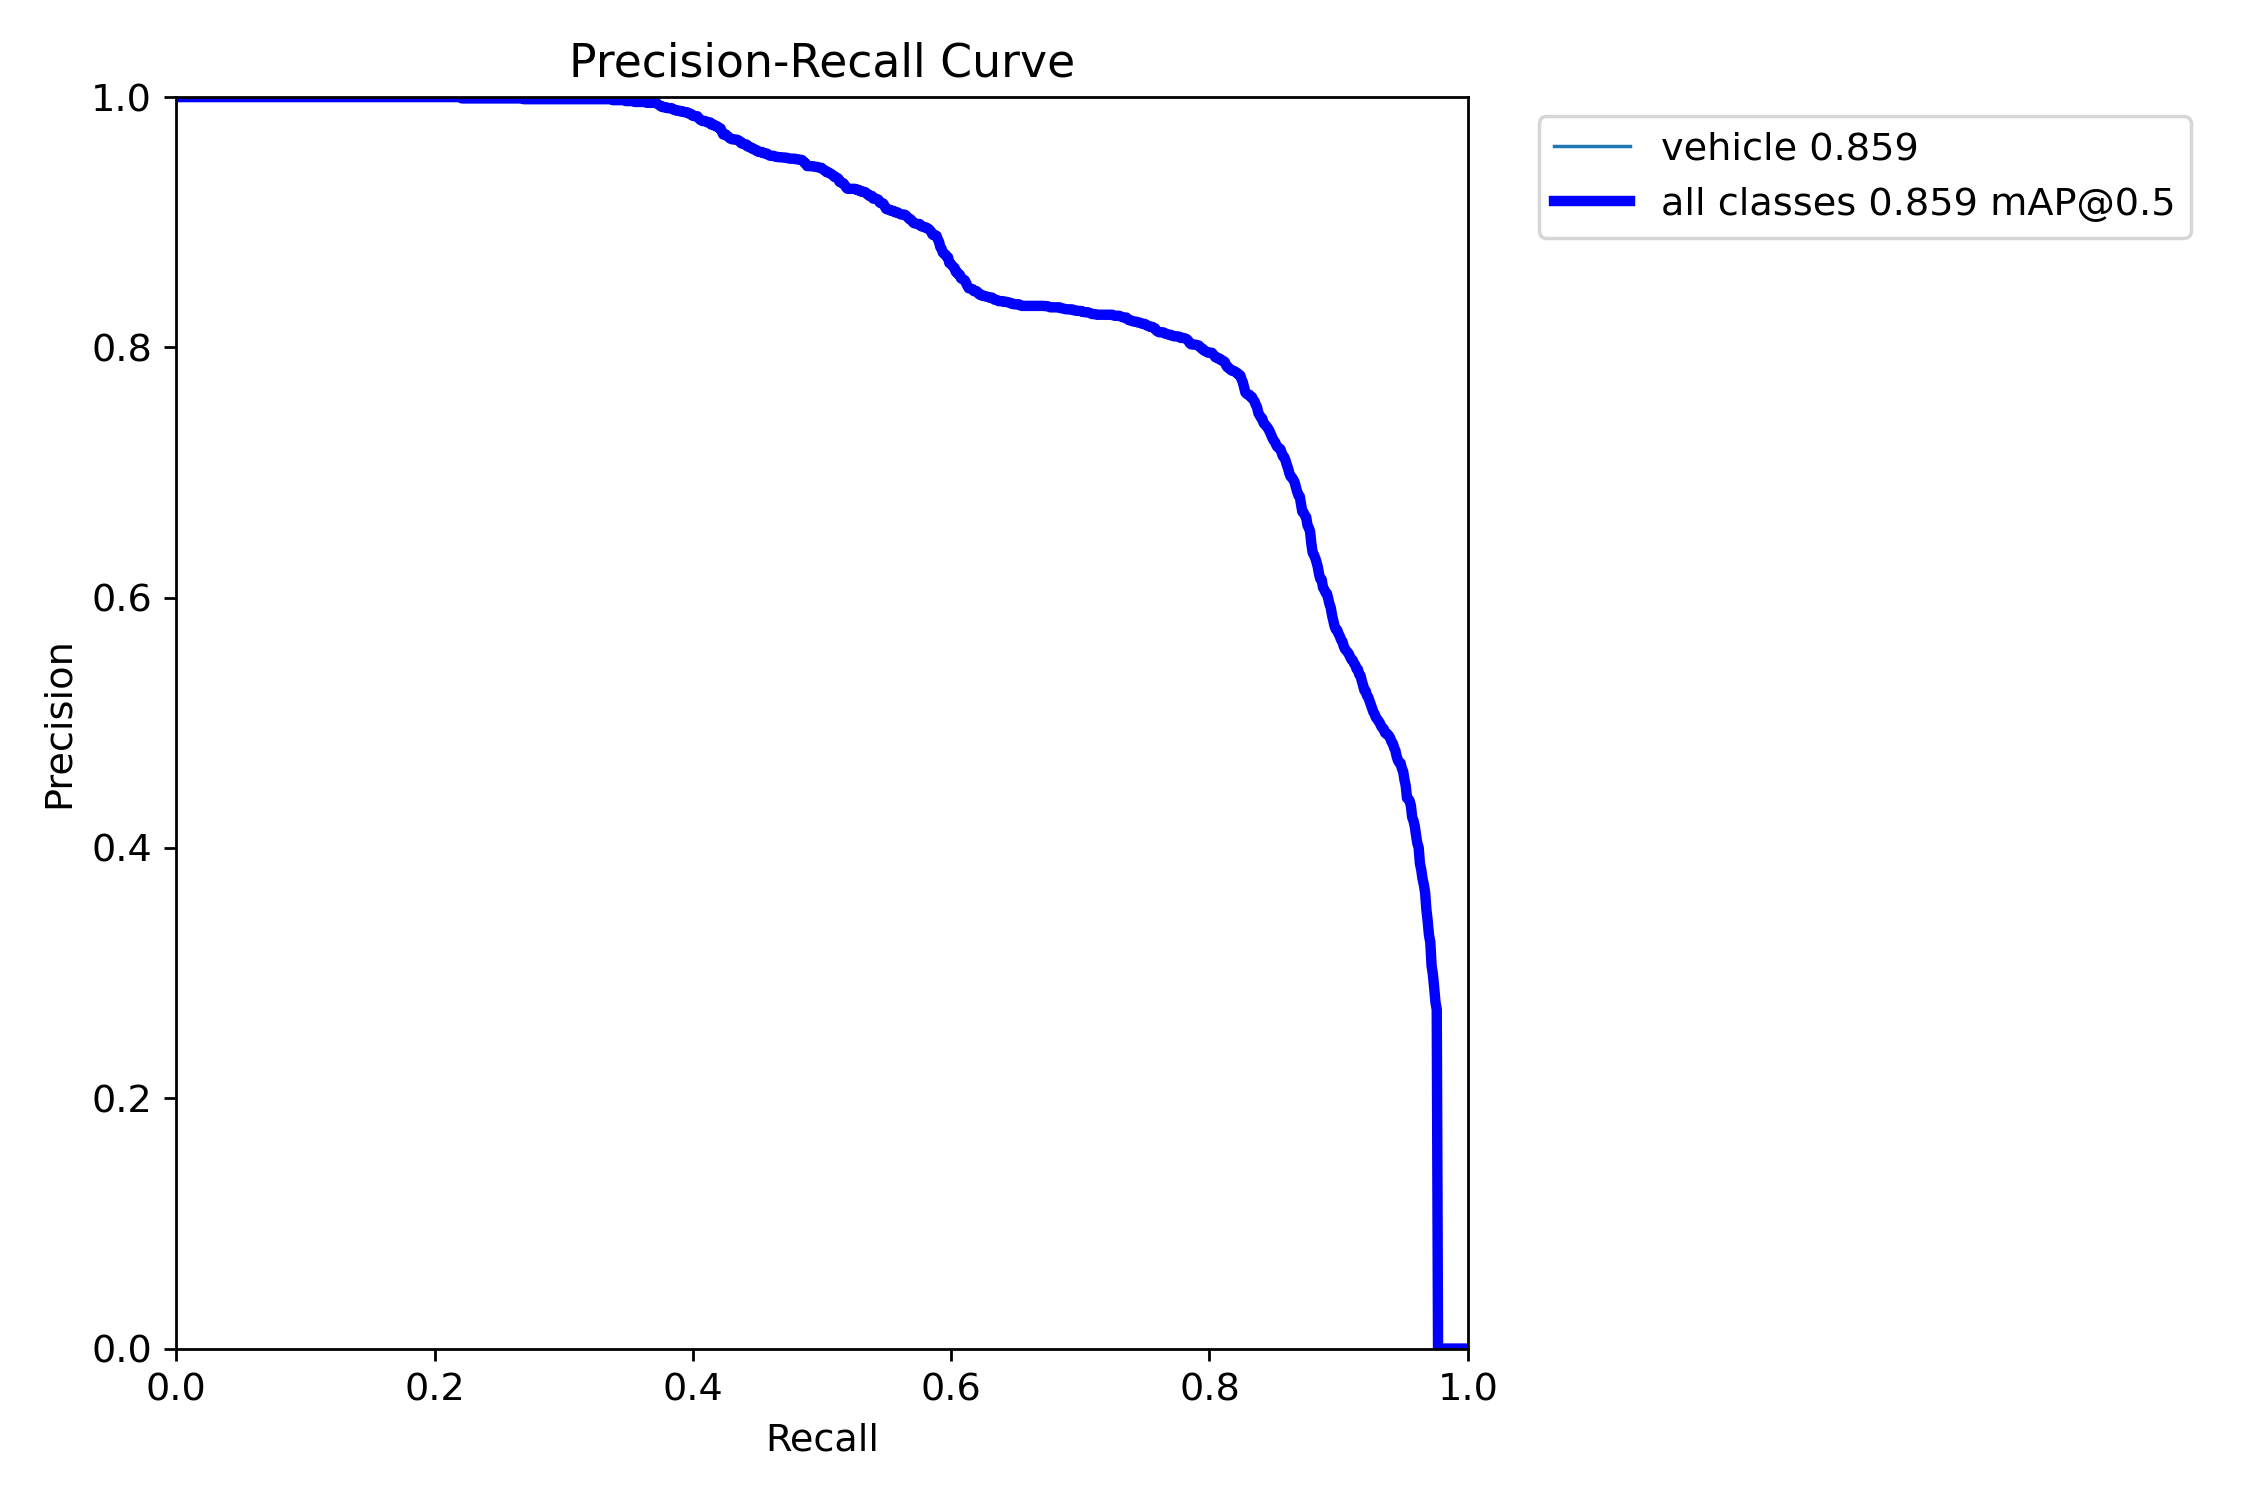

/content/det_eval/evaluate/BoxP_curve.png


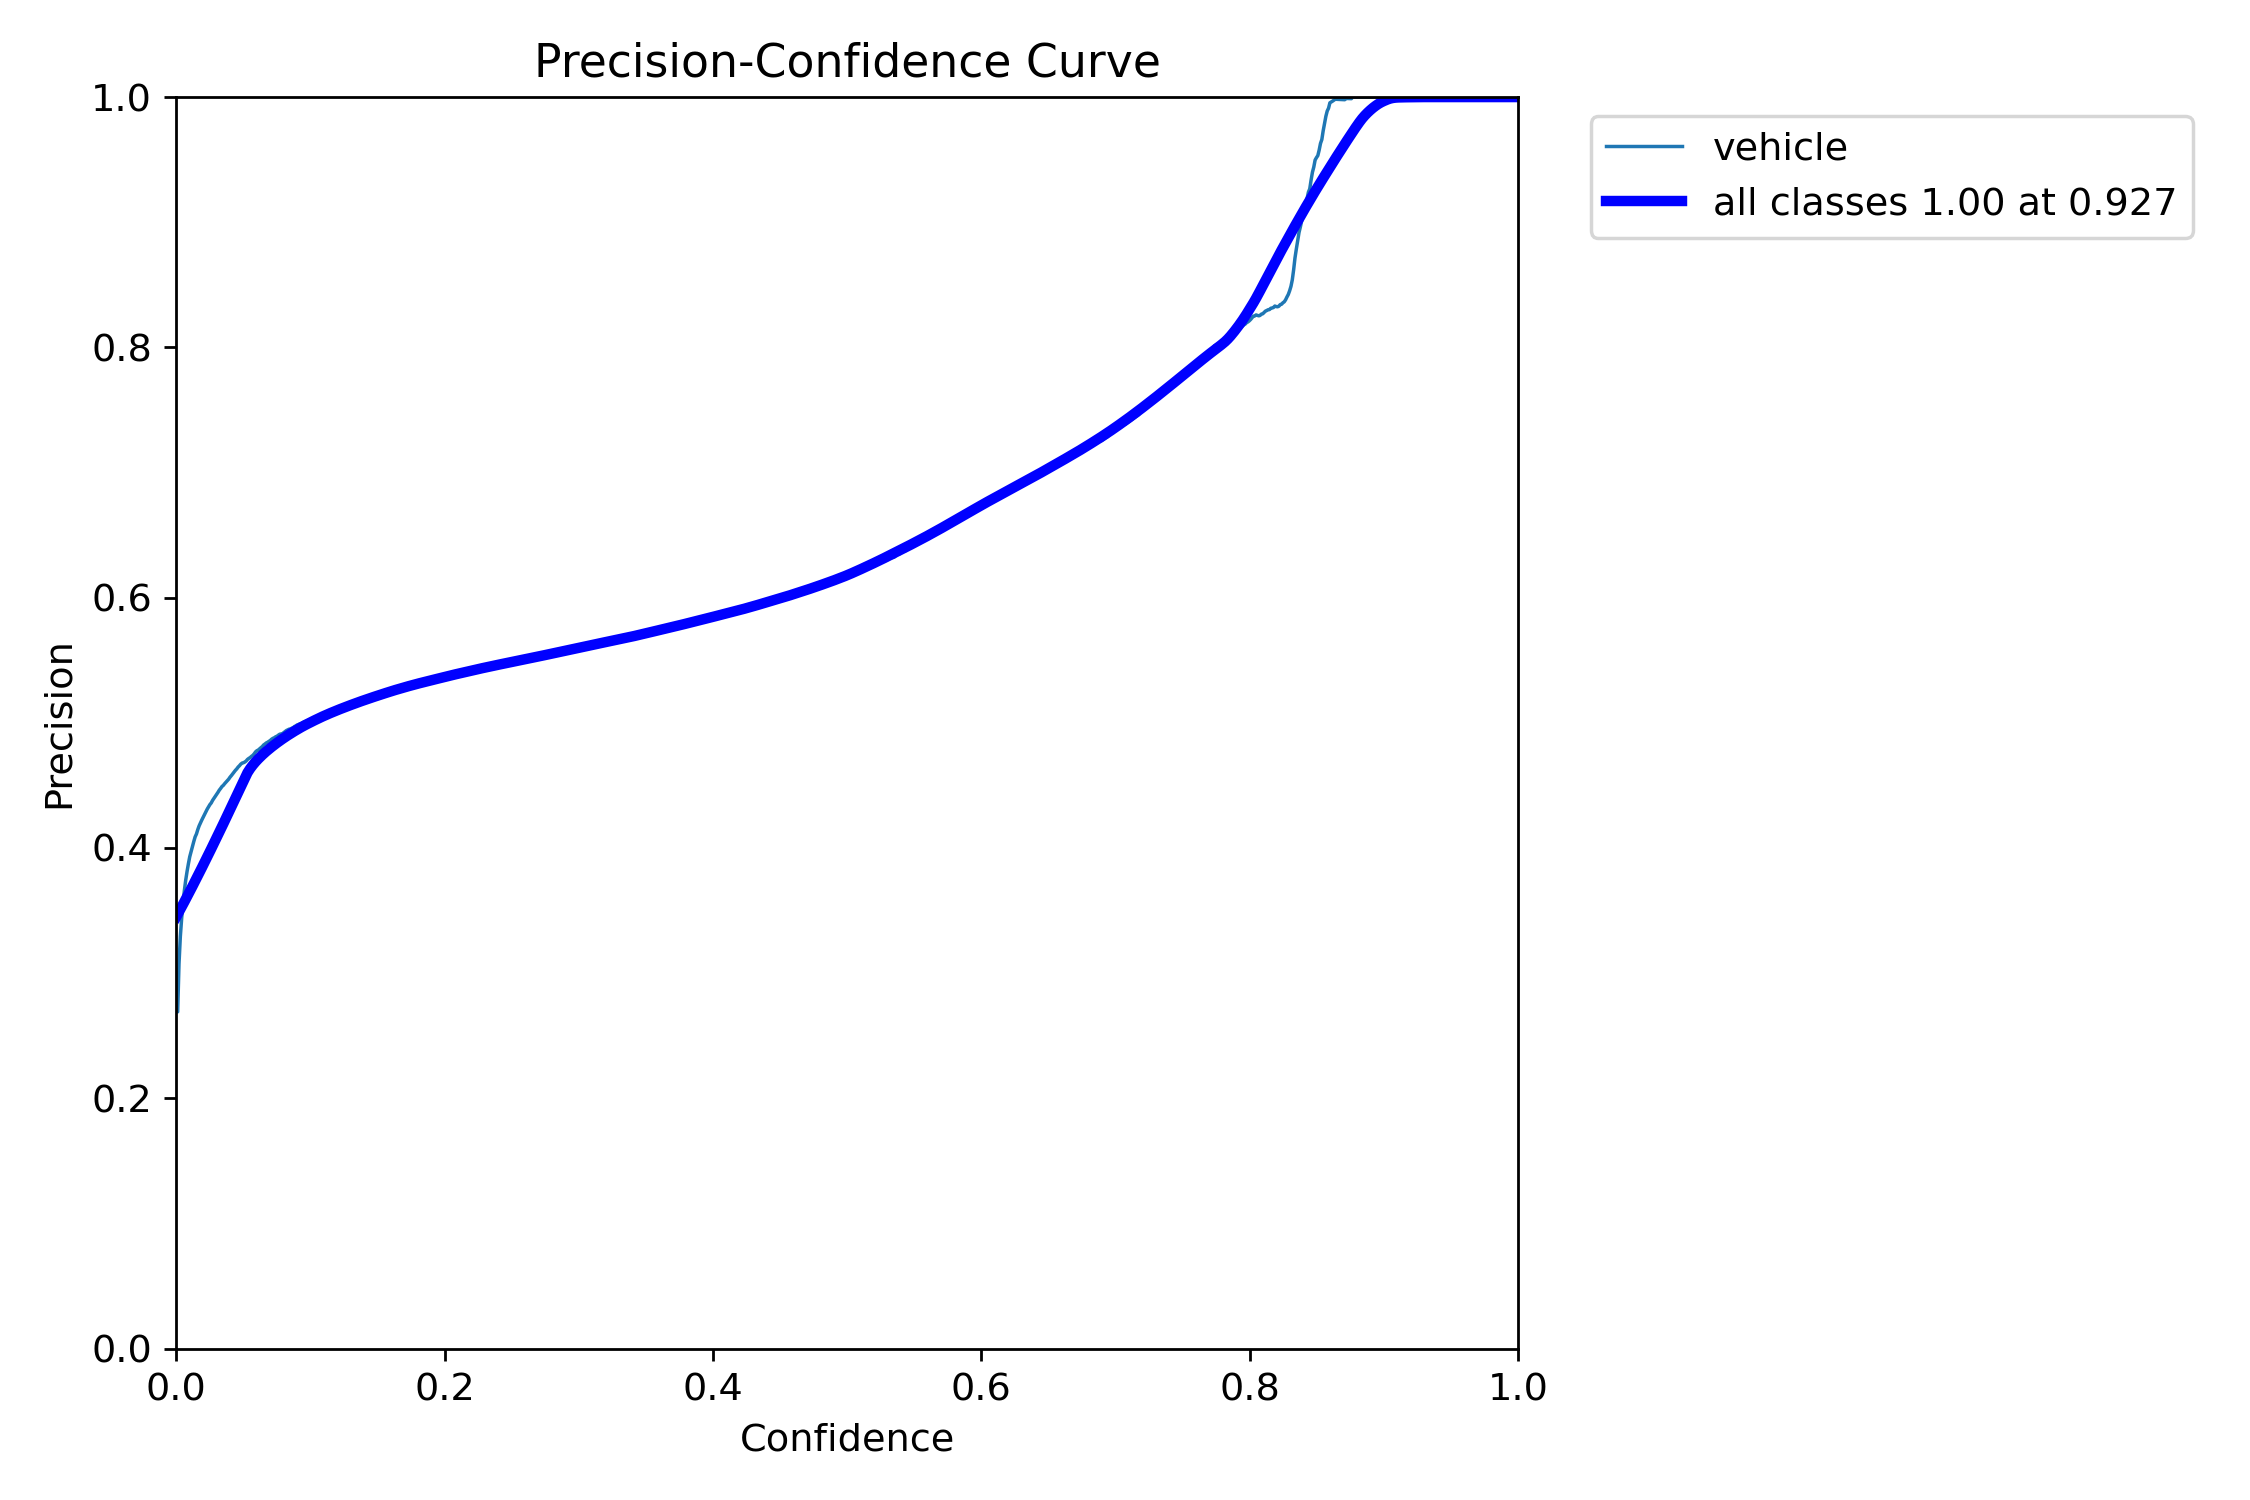

/content/det_eval/evaluate/BoxR_curve.png


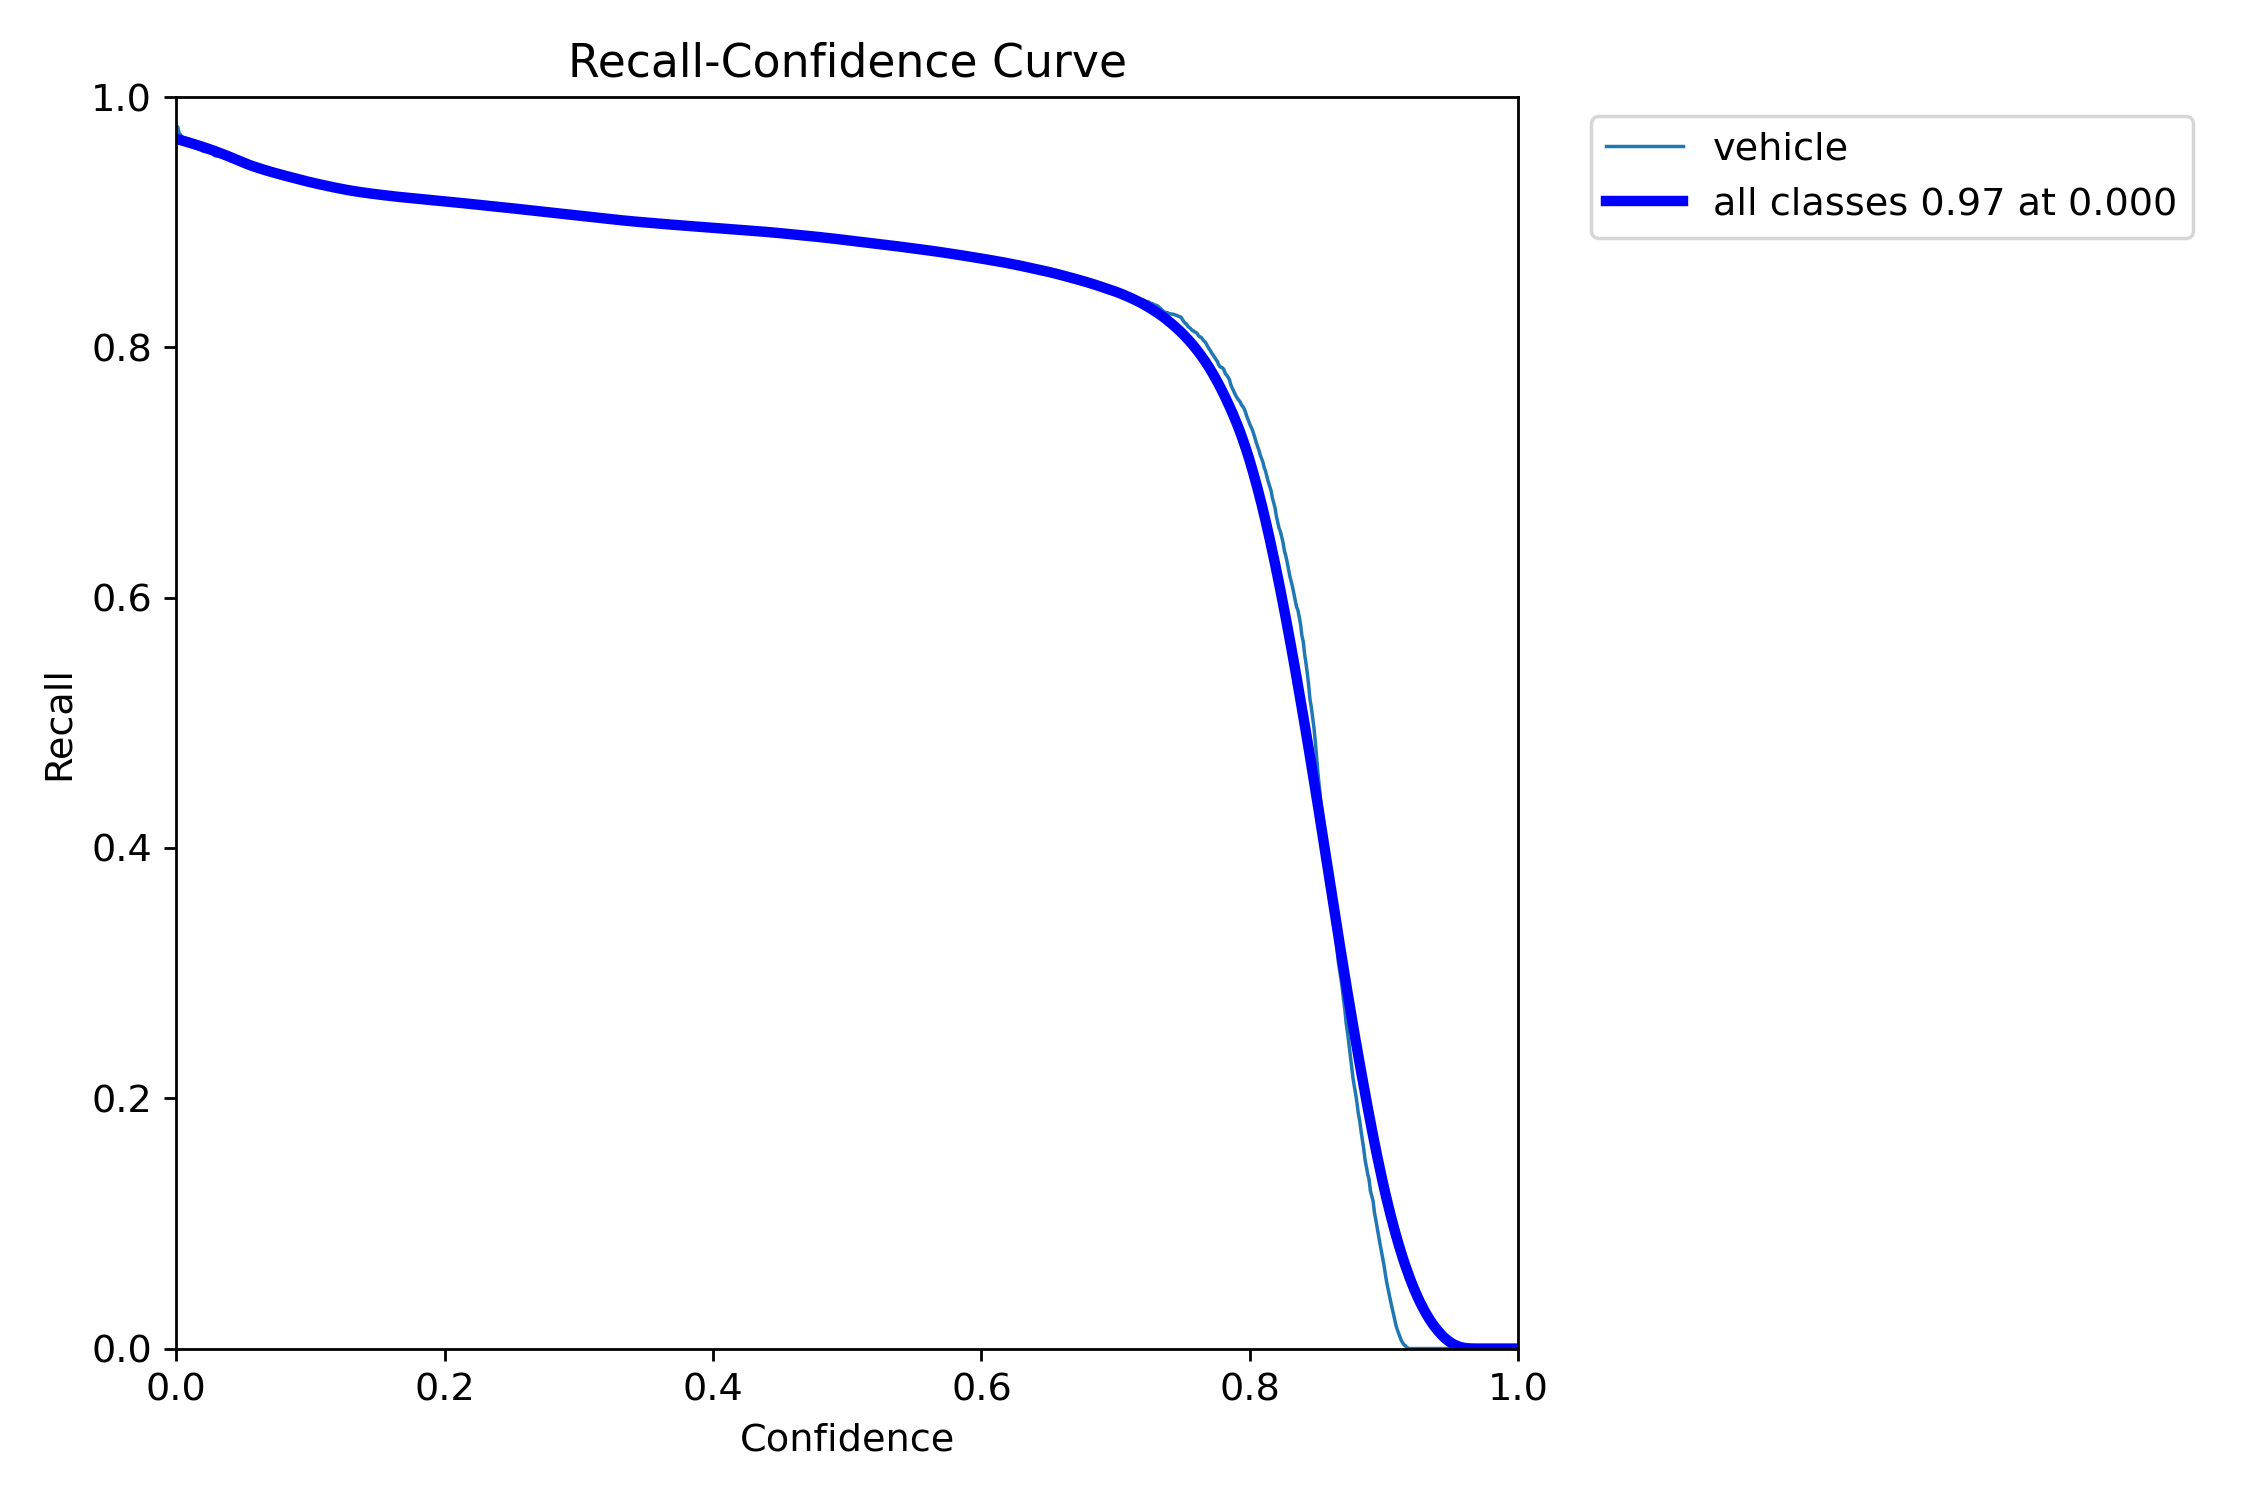

/content/det_eval/evaluate/confusion_matrix.png


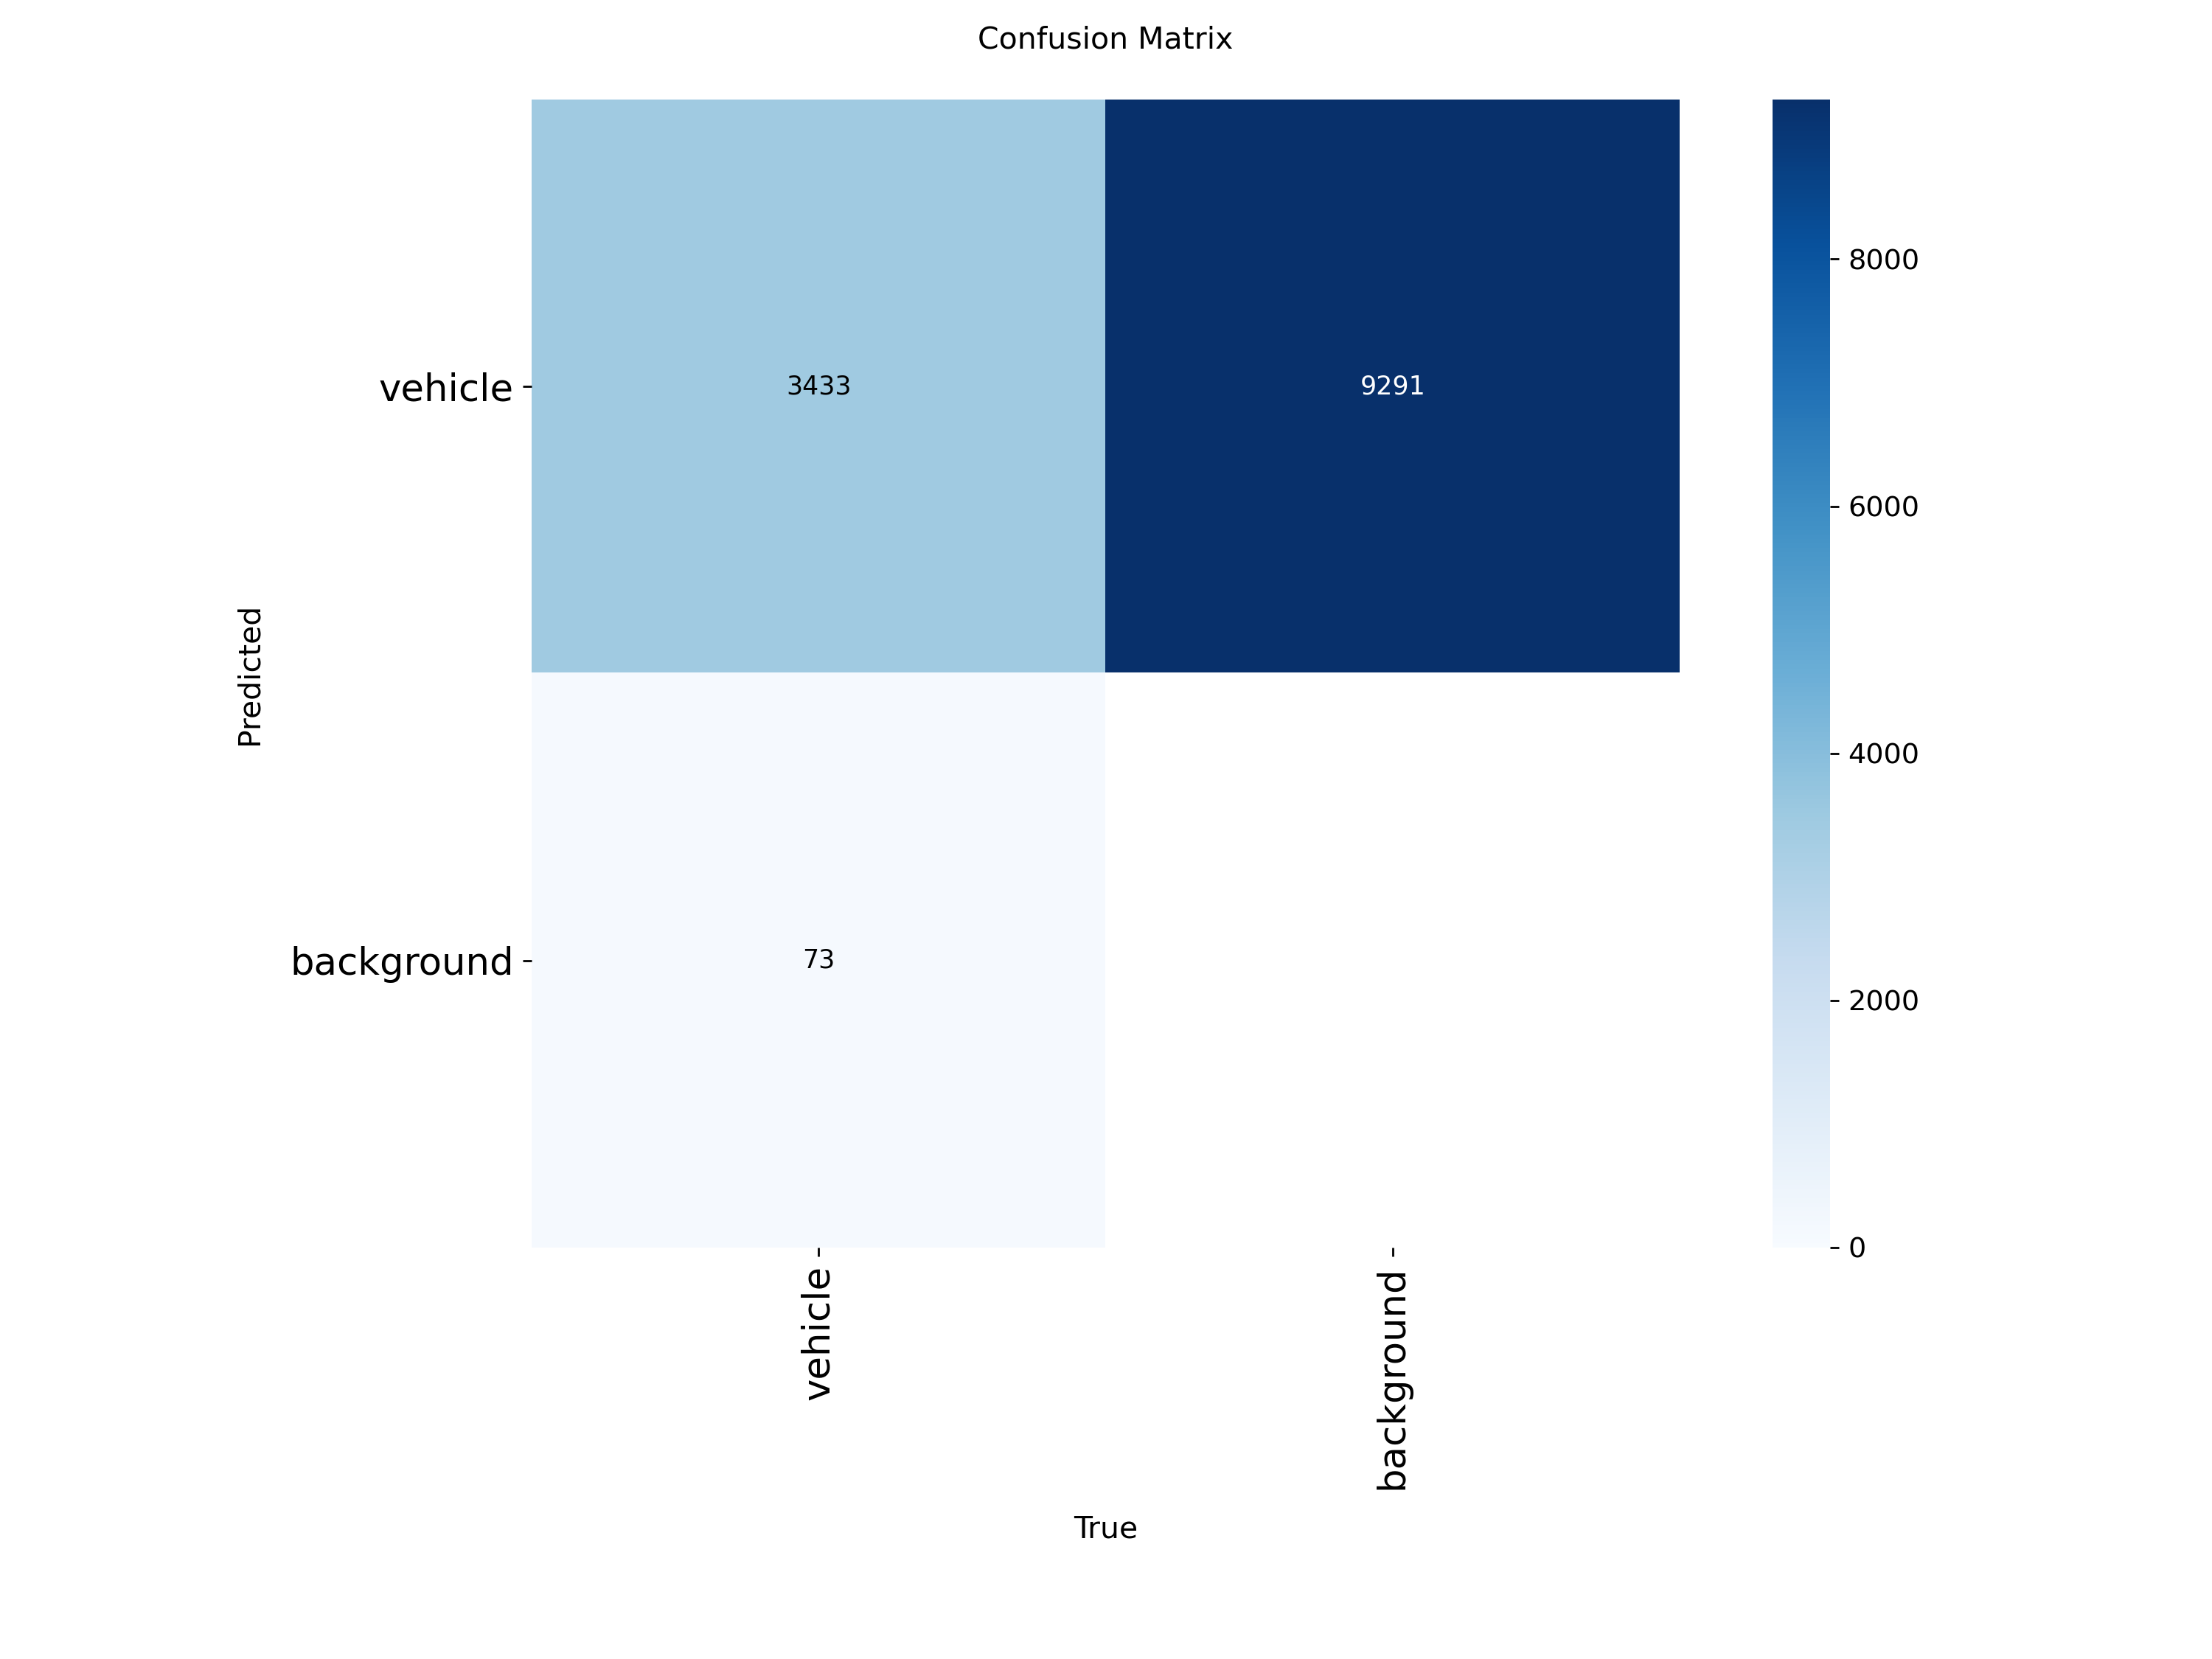

/content/det_eval/evaluate/confusion_matrix_normalized.png


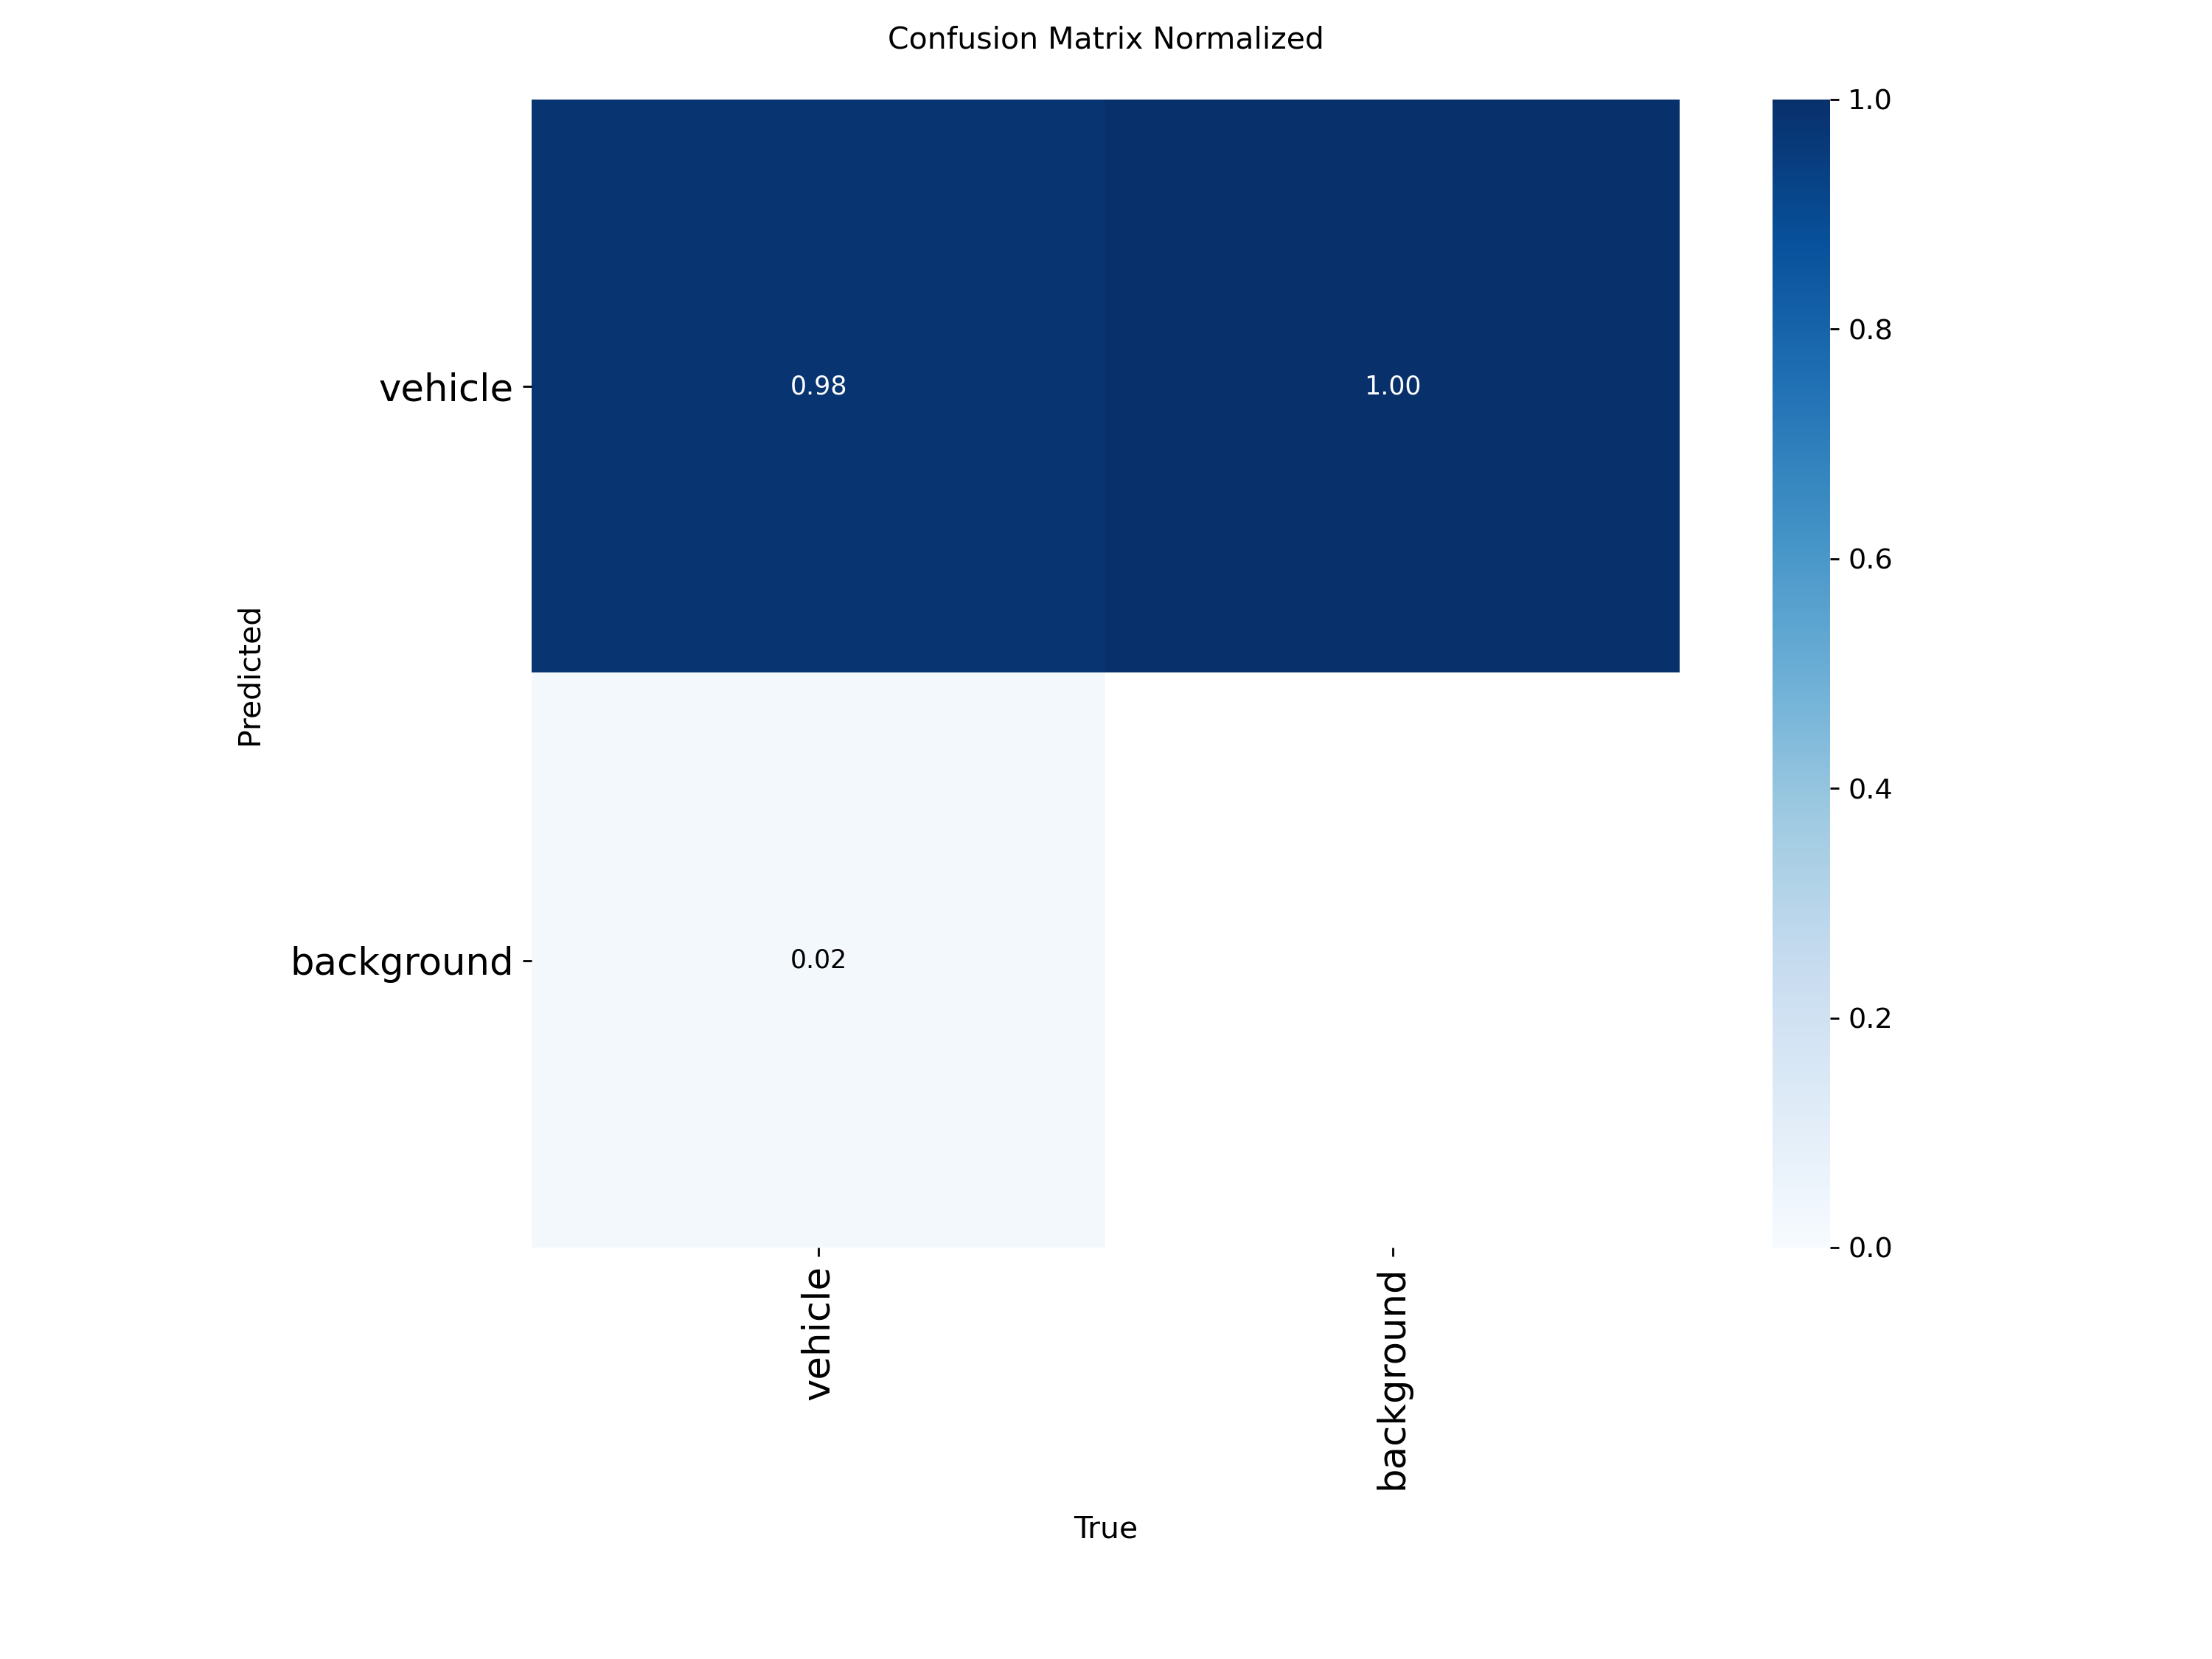

График обучения по эпохам: /content/drive/MyDrive/VehicleReID/detection_runs/vehicle_detector/results.png


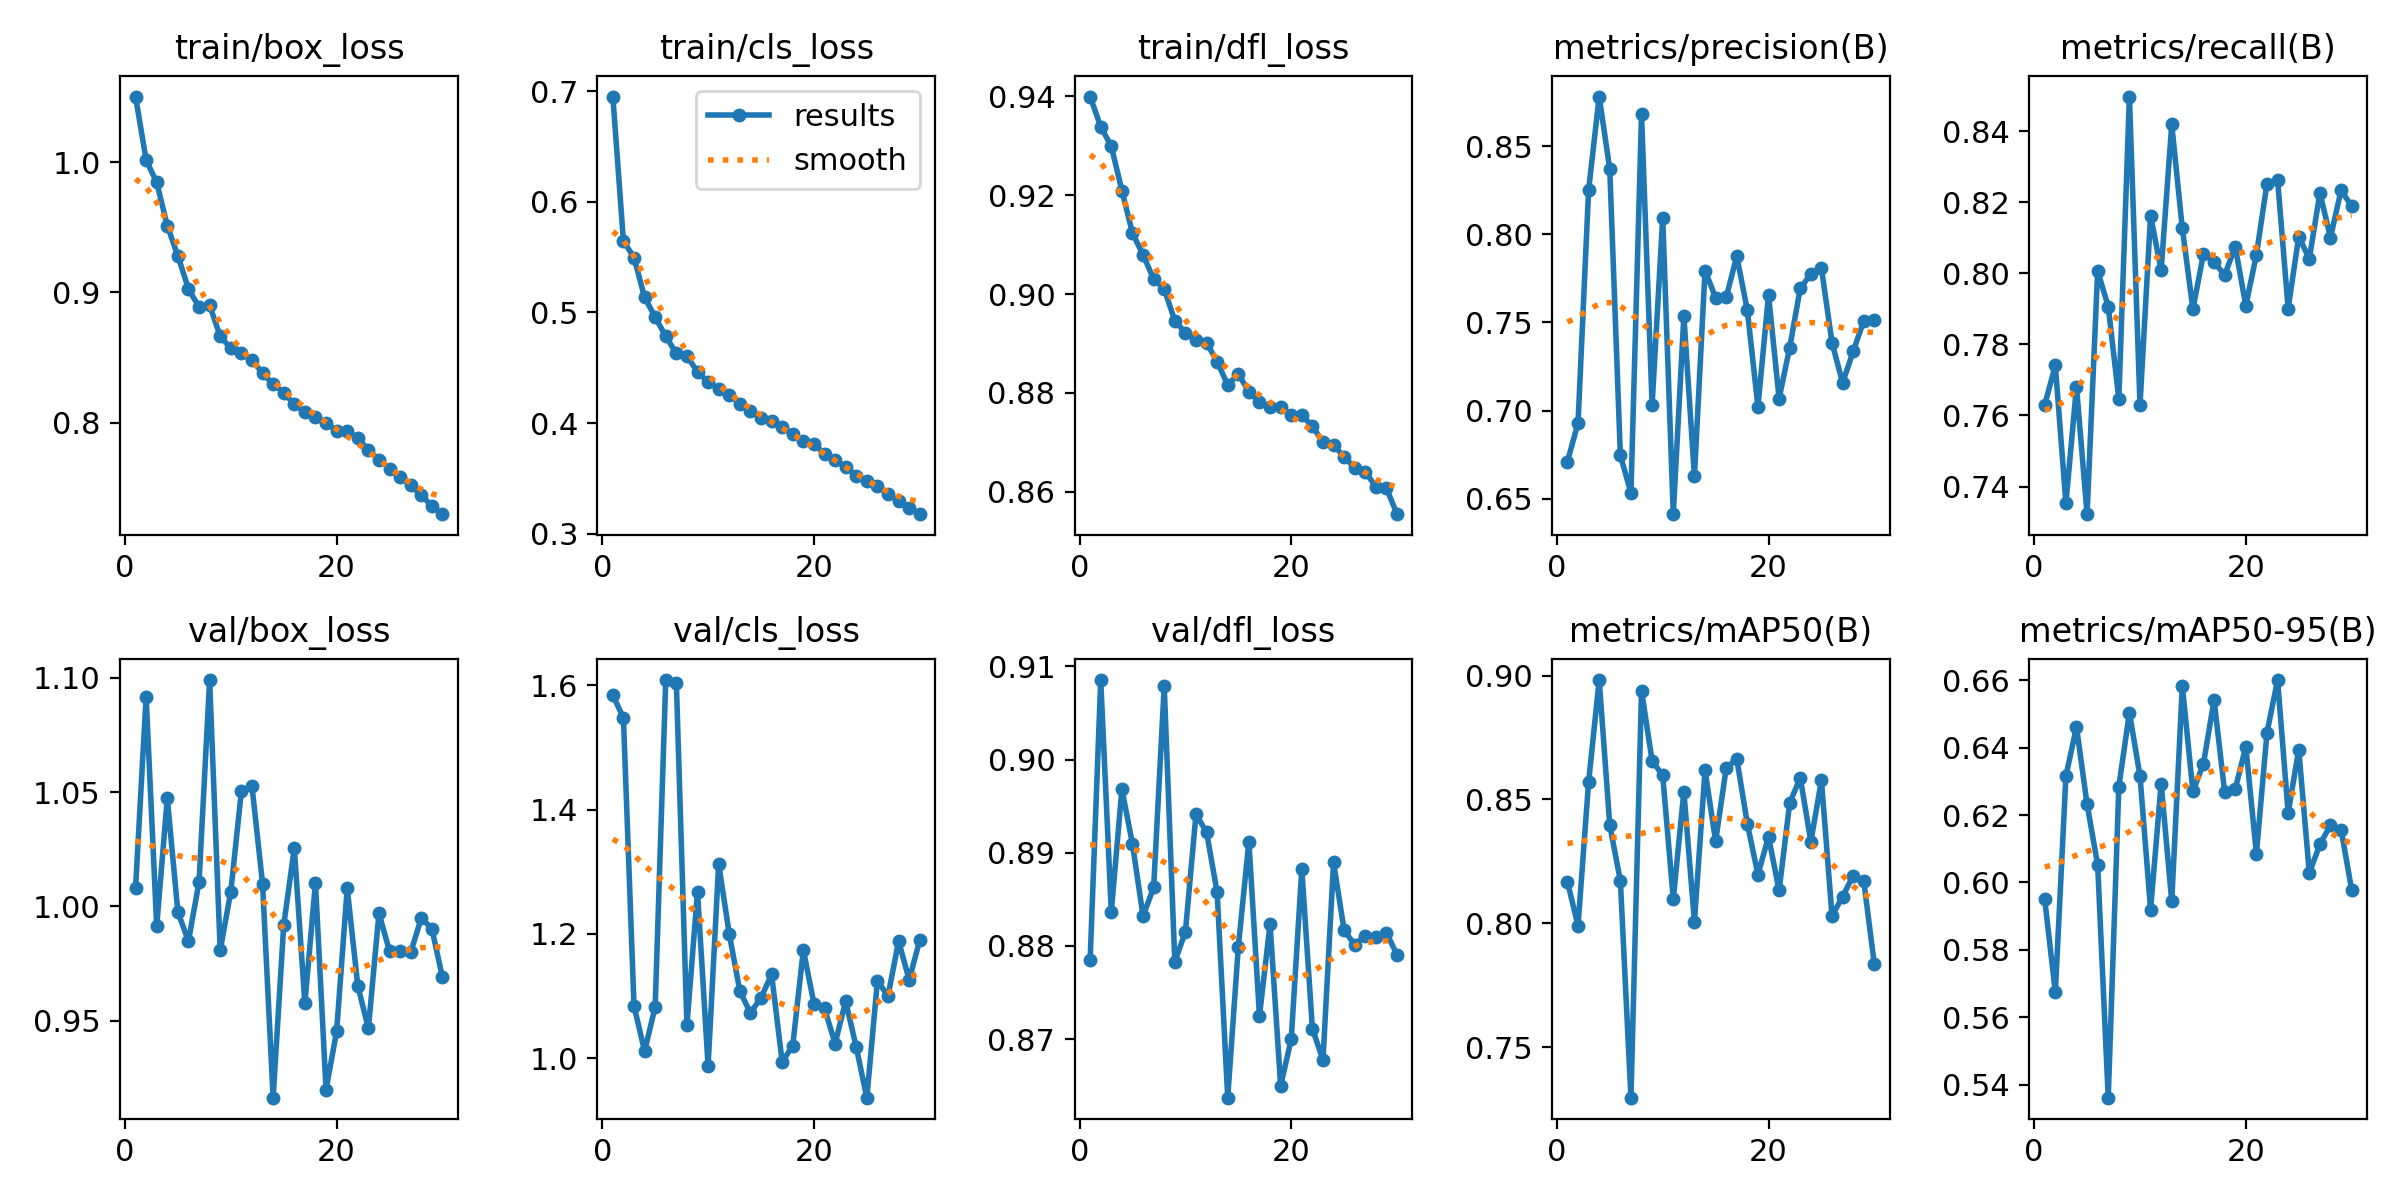

In [29]:
# 11. Графики для скриншотов: кривые PR/F1, матрица ошибок и график обучения по эпохам
from IPython.display import display, Image as IPImage
for p in sorted(glob.glob('/content/det_eval/evaluate/*.png'))[:6]:
    print(p); display(IPImage(p, width=600))
train_plot = os.path.join(os.path.dirname(os.path.dirname(DET_WEIGHTS)), 'results.png')
if os.path.isfile(train_plot):
    print('График обучения по эпохам:', train_plot); display(IPImage(train_plot, width=900))
else:
    print('results.png рядом с весами не найден:', train_plot)

In [15]:
# 12. Сводка и сохранение результатов на Drive
import re
def grab(path, key):
    m = re.findall(rf'{key}:\s*([\d.]+)', open(path, encoding='utf-8').read())
    return m[-1] if m else '?'
print('ReID, базовый режим      : mAP', grab('/content/reid_baseline.txt', 'mAP'),
      '| Rank-1', grab('/content/reid_baseline.txt', 'Rank-1'), '| Rank-5', grab('/content/reid_baseline.txt', 'Rank-5'))
print('ReID, TTA + re-ranking   : mAP', grab('/content/reid_tta_rerank.txt', 'mAP'),
      '| Rank-1', grab('/content/reid_tta_rerank.txt', 'Rank-1'), '| Rank-5', grab('/content/reid_tta_rerank.txt', 'Rank-5'))
txt = open('/content/det_metrics.txt', encoding='utf-8').read()
print('Детектор:'); print('\n'.join(l for l in txt.splitlines() if l.startswith(('Precision:', 'Recall:', 'mAP@50'))))
OUT = f'{ROOT}/eval_results'
os.makedirs(OUT, exist_ok=True)
for f in ['reid_baseline.txt', 'reid_tta_rerank.txt', 'det_metrics.txt']:
    shutil.copy(f'/content/{f}', OUT)
shutil.copytree('/content/det_eval', f'{OUT}/det_eval', dirs_exist_ok=True)
print('\nСохранено в', OUT)

ReID, базовый режим      : mAP 69.04 | Rank-1 93.33 | Rank-5 97.14
ReID, TTA + re-ranking   : mAP 73.91 | Rank-1 94.46 | Rank-5 96.48
Детектор:



FileNotFoundError: [Errno 2] No such file or directory: '/content/det_eval'